In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16, ResNet50, EfficientNetB0,DenseNet121
from tensorflow.keras.layers import Dense, Flatten, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
import matplotlib.pyplot as plt
import numpy as np
import os

In [3]:
import zipfile

zip_path = "/content/drive/MyDrive/ChestXRay2017.zip"
extract_path = "/content/extracted_images"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print(" Extraction completed")

 Extraction completed


In [4]:
train_dir = "/content/extracted_images/chest_xray/train"

test_dir  = "/content/extracted_images/chest_xray/test"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

In [5]:

from tensorflow.keras.preprocessing.image import ImageDataGenerator

# =====================================
# 1. TRAIN DATA - WITH AUGMENTATION
# =====================================

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    shear_range=0.1,
    horizontal_flip=True,
    width_shift_range=0.1,
    height_shift_range=0.1,
    validation_split=0.25
)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='training',
    shuffle=True,
    seed=42
)


# =====================================
# 2. VALIDATION DATA - NO AUGMENTATION
# =====================================

val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.25
)

val_gen = val_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation',
    shuffle=False,
    seed=42
)


# =====================================
# 3. TEST DATA - NO AUGMENTATION
# =====================================

test_datagen = ImageDataGenerator(
    rescale=1./255
)

test_gen = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=1,
    class_mode='binary',
    shuffle=False
)


# =====================================
# 4. PRINT IMAGE COUNTS
# =====================================

print("\n===== IMAGE COUNTS =====")

print("Training Images   :", train_gen.samples)
print("Validation Images :", val_gen.samples)
print("Testing Images    :", test_gen.samples)

print("\n===== CLASS INDICES =====")
print(train_gen.class_indices)

print("\n===== CLASS DISTRIBUTION =====")
print("Training:", train_gen.classes)
print("Validation:", val_gen.classes)
print("Testing:", test_gen.classes)


Found 3925 images belonging to 2 classes.
Found 1307 images belonging to 2 classes.
Found 624 images belonging to 2 classes.

===== IMAGE COUNTS =====
Training Images   : 3925
Validation Images : 1307
Testing Images    : 624

===== CLASS INDICES =====
{'NORMAL': 0, 'PNEUMONIA': 1}

===== CLASS DISTRIBUTION =====
Training: [0 0 0 ... 1 1 1]
Validation: [0 0 0 ... 1 1 1]
Testing: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 

In [6]:

import numpy as np

def show_class_distribution(generator, dataset_name):

    labels = generator.classes

    normal_count = np.sum(labels == 0)
    pneumonia_count = np.sum(labels == 1)

    print(f"\n===== {dataset_name} =====")
    print(f"NORMAL    : {normal_count}")
    print(f"PNEUMONIA : {pneumonia_count}")
    print(f"TOTAL     : {len(labels)}")


show_class_distribution(train_gen, "TRAINING DATA")
show_class_distribution(val_gen, "VALIDATION DATA")
show_class_distribution(test_gen, "TESTING DATA")


===== TRAINING DATA =====
NORMAL    : 1012
PNEUMONIA : 2913
TOTAL     : 3925

===== VALIDATION DATA =====
NORMAL    : 337
PNEUMONIA : 970
TOTAL     : 1307

===== TESTING DATA =====
NORMAL    : 234
PNEUMONIA : 390
TOTAL     : 624


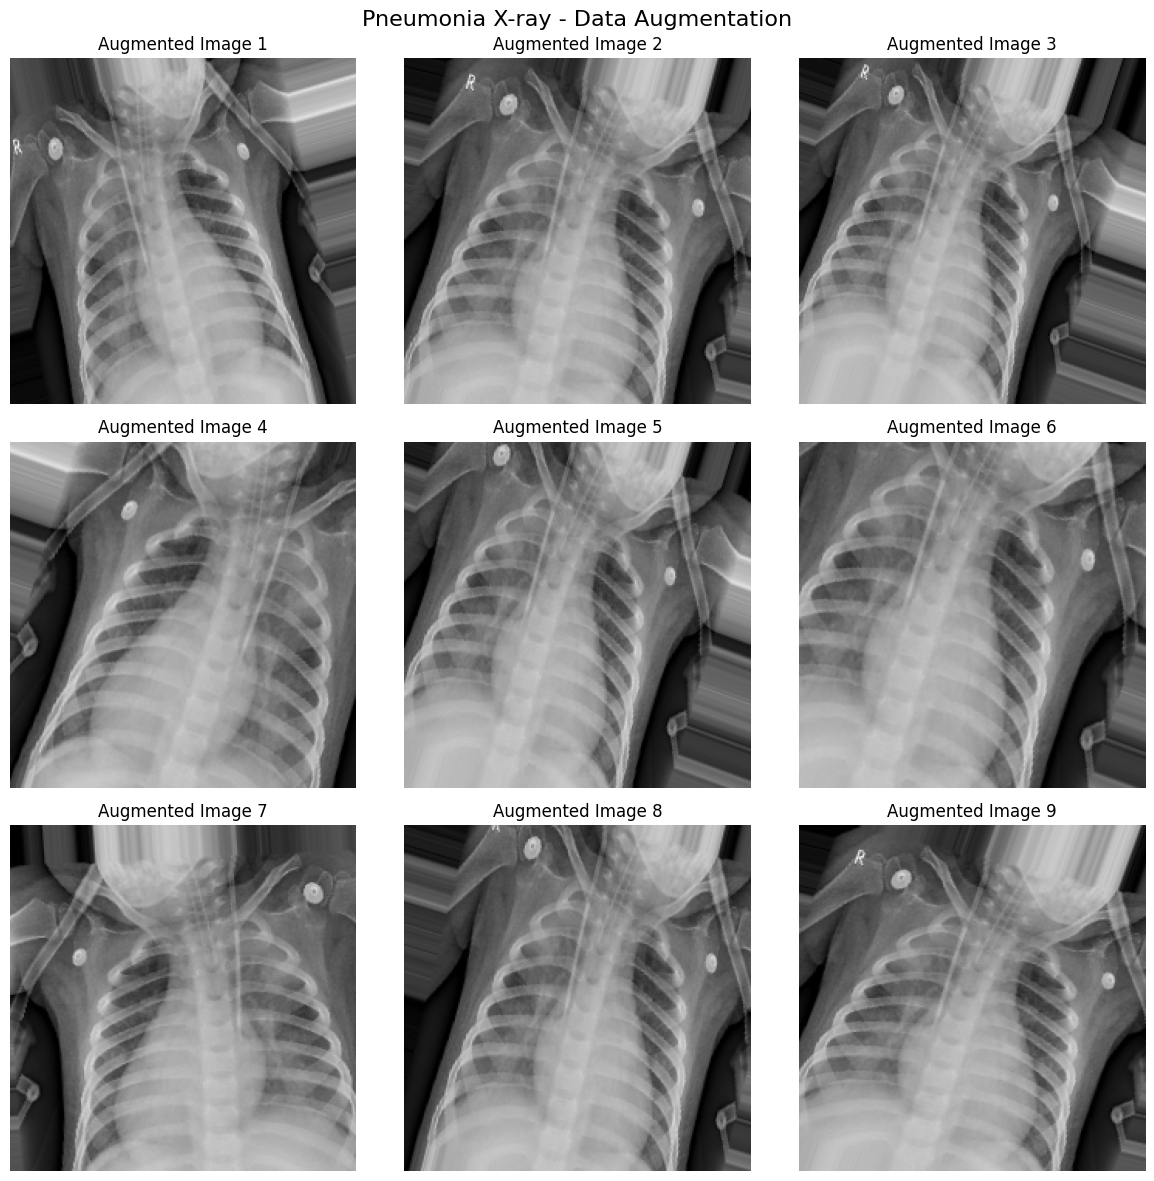

In [7]:
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import os
import random

# ==================================
# 1. Select Pneumonia Image
# ==================================

pneumonia_images_path = "/content/extracted_images/chest_xray/train/PNEUMONIA"

image_files = [
    f for f in os.listdir(pneumonia_images_path)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
]

# Randomly select one image
selected_image = random.choice(image_files)

img_path = os.path.join(pneumonia_images_path, selected_image)

# ==================================
# 2. Load Original Image
# ==================================

img = load_img(img_path, target_size=(224, 224))

img_array = img_to_array(img)
img_array = img_array.reshape((1,) + img_array.shape)

# ==================================
# 3. Generate Augmented Images
# ==================================

i = 0

plt.figure(figsize=(12, 12))

for batch in train_datagen.flow(img_array, batch_size=1):

    plt.subplot(3, 3, i + 1)

    plt.imshow(batch[0], vmin=0, vmax=1)

    plt.title(f"Augmented Image {i+1}")
    plt.axis('off')

    i += 1

    if i == 9:
        break

plt.suptitle(
    "Pneumonia X-ray - Data Augmentation",
    fontsize=16
)

plt.tight_layout()
plt.show()

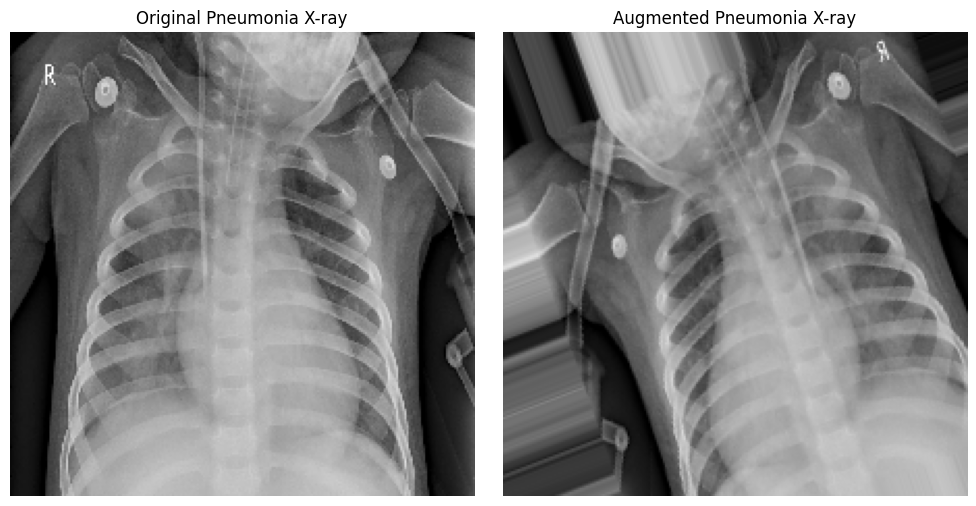

In [8]:

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 5))

# Original Image
plt.subplot(1, 2, 1)
plt.imshow(img_array[0] / 255.0)
plt.title("Original Pneumonia X-ray", fontsize=12)
plt.axis('off')

# Augmented Image
aug_img = next(train_datagen.flow(img_array, batch_size=1))[0]

plt.subplot(1, 2, 2)
plt.imshow(np.clip(aug_img, 0, 1))
plt.title("Augmented Pneumonia X-ray", fontsize=12)
plt.axis('off')

plt.tight_layout()
plt.show()


In [9]:
def build_model(base_model):
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(0.5)(x)
    output = Dense(1, activation='sigmoid')(x)

    model = Model(inputs=base_model.input, outputs=output)

    model.compile(
        optimizer=Adam(0.00001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

In [11]:
from tensorflow.keras.optimizers import Adam

base = VGG16(weights='imagenet', include_top=False, input_shape=(224,224,3))
model_vgg = build_model(base)
hist_vgg = model_vgg.fit(train_gen, validation_data=val_gen, epochs=10)

Epoch 1/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 234s 2s/step - accuracy: 0.8545 - loss: 0.3177 - val_accuracy: 0.9396 - val_loss: 0.1798
Epoch 2/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 175s 1s/step - accuracy: 0.9338 - loss: 0.1695 - val_accuracy: 0.9135 - val_loss: 0.2018
Epoch 3/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.9475 - loss: 0.1339 - val_accuracy: 0.9686 - val_loss: 0.0846
Epoch 4/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.9541 - loss: 0.1181 - val_accuracy: 0.9090 - val_loss: 0.2177
Epoch 5/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 147s 1s/step - accuracy: 0.9544 - loss: 0.1215 - val_accuracy: 0.9013 - val_loss: 0.2366
Epoch 6/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.9699 - loss: 0.0818 - val_accuracy: 0.9342 - val_loss: 0.1590
Epoch 7/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.9702 - loss: 0.0882 - val_accuracy: 0.7697 - val_loss: 0.6223
Epoch 8/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.9730 - loss: 0.0749 - val_accu

In [12]:
loss, accuracy = model_vgg.evaluate(test_gen)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.2f}")

624/624 ━━━━━━━━━━━━━━━━━━━━ 16s 22ms/step - accuracy: 0.9327 - loss: 0.1928
Test Loss: 0.1928
Test Accuracy: 0.93


In [13]:
base = ResNet50(weights='imagenet', include_top=False, input_shape=(224,224,3))
model_res = build_model(base)
hist_res = model_res.fit(train_gen, validation_data=val_gen, epochs=10)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 245s 1s/step - accuracy: 0.8380 - loss: 0.3480 - val_accuracy: 0.5448 - val_loss: 0.6905
Epoch 2/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 121s 978ms/step - accuracy: 0.9432 - loss: 0.1636 - val_accuracy: 0.7399 - val_loss: 0.6828
Epoch 3/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 127s 1s/step - accuracy: 0.9554 - loss: 0.1217 - val_accuracy: 0.7414 - val_loss: 0.6458
Epoch 4/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 127s 1s/step - accuracy: 0.9669 - loss: 0.0934 - val_accuracy: 0.7422 - val_loss: 0.7913
Epoch 5/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 128s 1s/step - accuracy: 0.9722 - loss: 0.0781 - val_accuracy: 0.7422 - val_loss: 1.2017
Epoch 6/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 124s 1s/step - accuracy: 0.9758 - loss: 0.0692 - val_accuracy: 0.7422 - val_loss: 1.8455
Epoch 7/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 148s 1s/step - accuracy: 0.9799 - loss: 0.0571 - val_accuracy: 0.7422 - val_loss: 1.7211
Epoch 8/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 130

In [14]:
loss, accuracy = model_res.evaluate(test_gen)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.2f}")

624/624 ━━━━━━━━━━━━━━━━━━━━ 16s 20ms/step - accuracy: 0.7997 - loss: 0.6175
Test Loss: 0.6175
Test Accuracy: 0.80


In [15]:
from tensorflow.keras.applications import DenseNet121
base = DenseNet121(weights='imagenet', include_top=False, input_shape=(224,224,3))
model_dense = build_model(base)
hist_dense = model_dense.fit(train_gen, validation_data=val_gen, epochs=10)

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 587s 3s/step - accuracy: 0.7595 - loss: 0.4882 - val_accuracy: 0.7429 - val_loss: 0.6583
Epoch 2/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 127s 1s/step - accuracy: 0.9075 - loss: 0.2296 - val_accuracy: 0.7567 - val_loss: 0.6300
Epoch 3/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 127s 1s/step - accuracy: 0.9383 - loss: 0.1682 - val_accuracy: 0.7972 - val_loss: 0.4764
Epoch 4/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 130s 1s/step - accuracy: 0.9480 - loss: 0.1391 - val_accuracy: 0.9051 - val_loss: 0.1996
Epoch 5/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 129s 1s/step - accuracy: 0.9524 - loss: 0.1310 - val_accuracy: 0.9748 - val_loss: 0.0791
Epoch 6/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 122s 995ms/step - accuracy: 0.9641 - loss: 0.1047 - val_accuracy: 0.9441 - val_loss: 0.1397
Epoch 7/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 124s 1s/step - accuracy: 0.9671 - loss: 0.0914 - val_accuracy: 0.9380 - val_loss: 0.1577
Epoch 8/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 123

In [16]:
loss, accuracy = model_dense.evaluate(test_gen)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.2f}")

624/624 ━━━━━━━━━━━━━━━━━━━━ 26s 20ms/step - accuracy: 0.9071 - loss: 0.2354
Test Loss: 0.2354
Test Accuracy: 0.91


In [17]:
print("VGG16:", model_vgg.evaluate(test_gen))
print("ResNet50:", model_res.evaluate(test_gen))
print("DenseNet121:", model_dense.evaluate(test_gen))

624/624 ━━━━━━━━━━━━━━━━━━━━ 13s 20ms/step - accuracy: 0.9327 - loss: 0.1928
VGG16: [0.19284702837467194, 0.932692289352417]
624/624 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.7997 - loss: 0.6175
ResNet50: [0.617515504360199, 0.7996794581413269]
624/624 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.9071 - loss: 0.2354
DenseNet121: [0.23543216288089752, 0.9070512652397156]


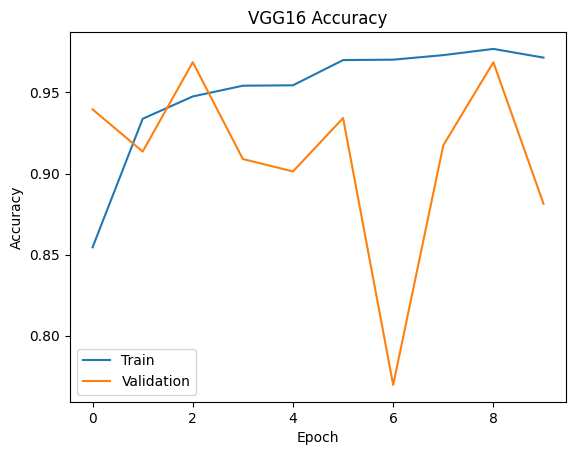

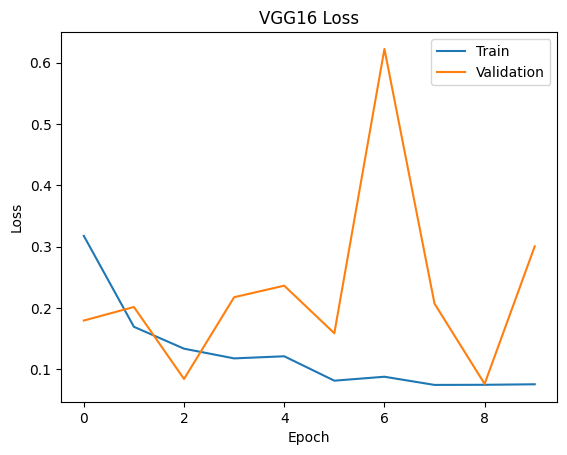

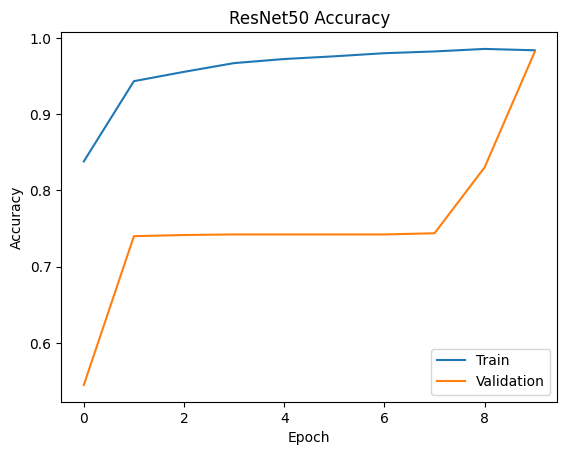

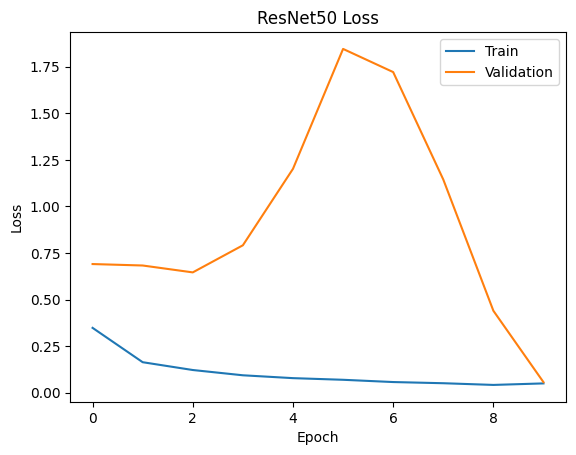

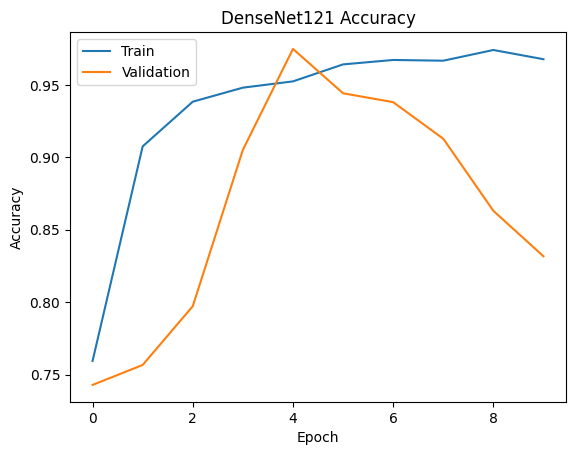

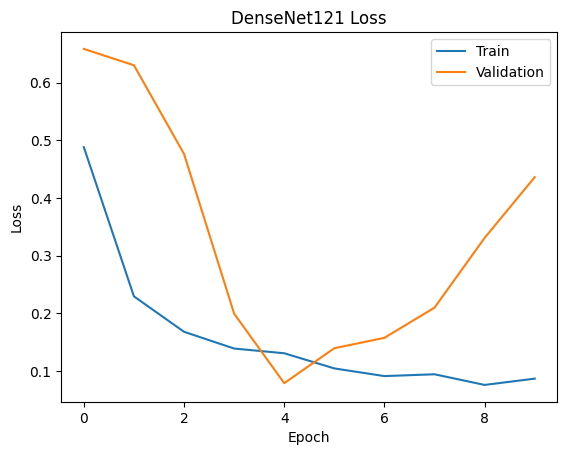

In [18]:

import matplotlib.pyplot as plt

histories = {
    'VGG16': hist_vgg,
    'ResNet50': hist_res,
    'DenseNet121': hist_dense


}

for name, history in histories.items():

    # Accuracy Plot
    plt.figure()
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title(f'{name} Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(['Train', 'Validation'])
    plt.show()

    # Loss Plot
    plt.figure()
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title(f'{name} Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(['Train', 'Validation'])
    plt.show()

In [19]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [20]:
all_predictions = {}
all_true = test_gen.classes   # True labels

models = {
    'VGG16': model_vgg,
    'ResNet50': model_res,
    'DenseNet121': model_dense


}

for name, model in models.items():
    print(f"\nEvaluating {name}...")

    preds = model.predict(test_gen)
    preds = (preds > 0.5).astype(int).reshape(-1)

    all_predictions[name] = preds


Evaluating VGG16...
624/624 ━━━━━━━━━━━━━━━━━━━━ 13s 20ms/step

Evaluating ResNet50...
624/624 ━━━━━━━━━━━━━━━━━━━━ 20s 19ms/step

Evaluating DenseNet121...
624/624 ━━━━━━━━━━━━━━━━━━━━ 30s 30ms/step


In [21]:
for name, preds in all_predictions.items():
    print(f"\n {name} Classification Report:")

    print(classification_report(all_true, preds, target_names=["Normal", "Pneumonia"]))


 VGG16 Classification Report:
              precision    recall  f1-score   support

      Normal       0.92      0.90      0.91       234
   Pneumonia       0.94      0.95      0.95       390

    accuracy                           0.93       624
   macro avg       0.93      0.93      0.93       624
weighted avg       0.93      0.93      0.93       624


 ResNet50 Classification Report:
              precision    recall  f1-score   support

      Normal       0.97      0.48      0.64       234
   Pneumonia       0.76      0.99      0.86       390

    accuracy                           0.80       624
   macro avg       0.87      0.74      0.75       624
weighted avg       0.84      0.80      0.78       624


 DenseNet121 Classification Report:
              precision    recall  f1-score   support

      Normal       0.83      0.94      0.88       234
   Pneumonia       0.96      0.88      0.92       390

    accuracy                           0.91       624
   macro avg       0.90   

In [22]:

import numpy as np
from sklearn.metrics import confusion_matrix

def calculate_sensitivity_specificity(y_true, y_pred):

    # Confusion Matrix
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    # Sensitivity (Recall for Pneumonia)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0

    # Specificity (Recall for Normal)
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

    print(f"Sensitivity: {sensitivity:.4f} ({sensitivity*100:.2f}%)")
    print(f"Specificity: {specificity:.4f} ({specificity*100:.2f}%)")

    return sensitivity, specificity

In [23]:
# Example: test generator labels
y_true = test_gen.classes

# Calculate sensitivity and specificity for each model in all_predictions
for model_name, y_pred in all_predictions.items():

    print("\n==========", model_name, "==========")

    sensitivity, specificity = calculate_sensitivity_specificity(
        y_true, y_pred
    )


========== VGG16 ==========
Confusion Matrix:
[[211  23]
 [ 19 371]]
Sensitivity: 0.9513 (95.13%)
Specificity: 0.9017 (90.17%)

========== ResNet50 ==========
Confusion Matrix:
[[112 122]
 [  3 387]]
Sensitivity: 0.9923 (99.23%)
Specificity: 0.4786 (47.86%)

========== DenseNet121 ==========
Confusion Matrix:
[[221  13]
 [ 45 345]]
Sensitivity: 0.8846 (88.46%)
Specificity: 0.9444 (94.44%)


In [24]:
def plot_confusion_matrix(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure()
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

    plt.title(f"{model_name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()

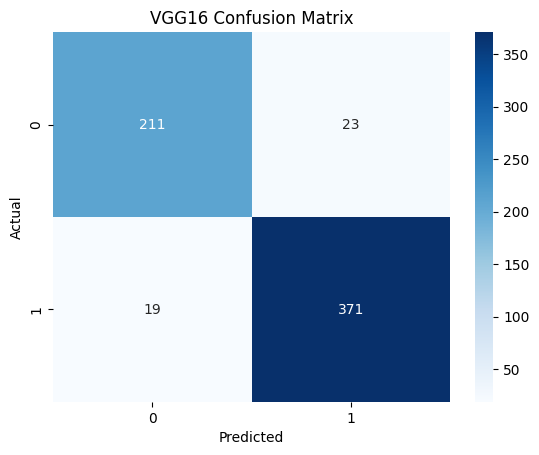

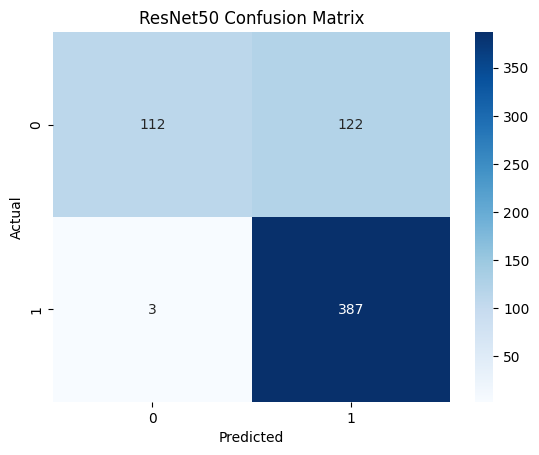

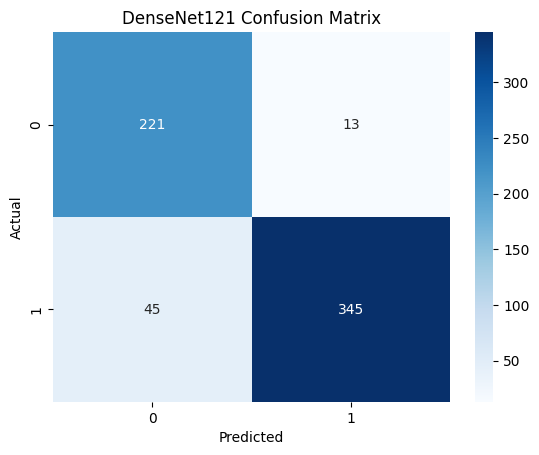

In [25]:
for name, preds in all_predictions.items():
    plot_confusion_matrix(all_true, preds, name)

In [26]:
accuracies = {}

for name, preds in all_predictions.items():
    acc = accuracy_score(all_true, preds)
    accuracies[name] = acc
    print(f"{name} Accuracy: {acc:.4f}")

VGG16 Accuracy: 0.9327
ResNet50 Accuracy: 0.7997
DenseNet121 Accuracy: 0.9071



Processing VGG16...
624/624 ━━━━━━━━━━━━━━━━━━━━ 14s 22ms/step

Processing ResNet50...
624/624 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step

Processing DenseNet121...
624/624 ━━━━━━━━━━━━━━━━━━━━ 13s 21ms/step


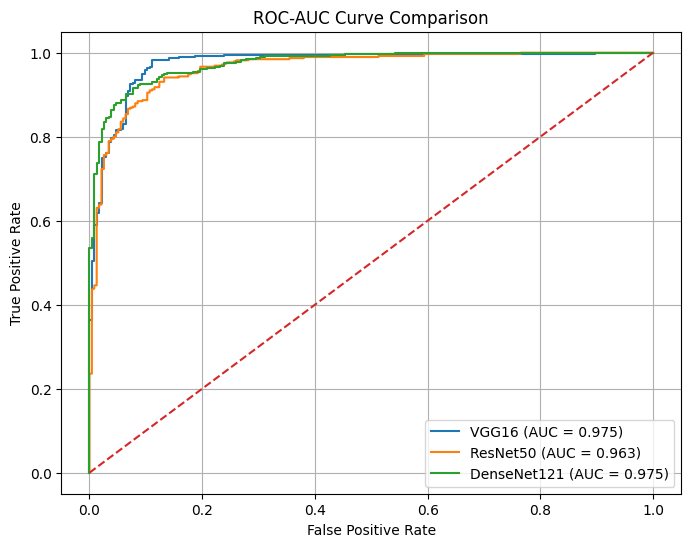

In [27]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

all_probs = {}   # store probabilities
y_true = test_gen.classes   # true labels

models = {
    'VGG16': model_vgg,
    'ResNet50': model_res,
    'DenseNet121': model_dense



}

#  Get probabilities (NOT thresholded)
for name, model in models.items():
    print(f"\nProcessing {name}...")

    probs = model.predict(test_gen)
    probs = probs.ravel()   # flatten

    all_probs[name] = probs


#  Plot ROC curves
plt.figure(figsize=(8,6))

for name, probs in all_probs.items():
    fpr, tpr, _ = roc_curve(y_true, probs)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.3f})')

# Random line
plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve Comparison')
plt.legend(loc='lower right')
plt.grid()

plt.show()

In [28]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    balanced_accuracy_score,
    cohen_kappa_score,
    log_loss,
    brier_score_loss
)

from sklearn.utils import resample


# ==========================================
# RESEARCH EVALUATION FUNCTION
# ==========================================

def evaluate_research_metrics(
    y_true,
    y_pred,
    y_prob,
    model_name
):

    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    y_prob = np.asarray(y_prob).astype(float)

    # Confusion Matrix
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    # Basic Metrics
    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true, y_pred, zero_division=0
    )

    sensitivity = recall_score(
        y_true, y_pred, zero_division=0
    )

    specificity = (
        tn / (tn + fp) if (tn + fp) > 0 else 0
    )

    f1 = f1_score(
        y_true, y_pred, zero_division=0
    )

    # Additional Metrics
    npv = tn / (tn + fn) if (tn + fn) > 0 else 0

    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0

    mcc = matthews_corrcoef(y_true, y_pred)

    balanced_acc = balanced_accuracy_score(
        y_true, y_pred
    )

    kappa = cohen_kappa_score(y_true, y_pred)

    # Probability Metrics
    roc_auc = roc_auc_score(y_true, y_prob)

    pr_auc = average_precision_score(y_true, y_prob)

    logloss = log_loss(
        y_true, y_prob, labels=[0, 1]
    )

    brier = brier_score_loss(y_true, y_prob)

    # Store Results
    results = {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "F1-Score": f1,
        "NPV": npv,
        "MCC": mcc,
        "Balanced Accuracy": balanced_acc,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc,
        "Cohen Kappa": kappa,
        "FPR": fpr,
        "FNR": fnr,
        "Log Loss": logloss,
        "Brier Score": brier,
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn
    }

    # Print Results
    print("\n" + "=" * 60)
    print(f"{model_name} - RESEARCH EVALUATION")
    print("=" * 60)

    for metric, value in results.items():

        if isinstance(value, (float, np.floating)):
            print(f"{metric:20s}: {value:.4f}")
        else:
            print(f"{metric:20s}: {value}")

    print("\nClassification Report:")

    print(
        classification_report(
            y_true,
            y_pred,
            labels=[0, 1],
            target_names=["Normal", "Pneumonia"],
            zero_division=0
        )
    )

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

    return results

In [29]:
# Generate prediction probabilities for each model
vgg_prob = model_vgg.predict(test_gen).ravel()
resnet_prob = model_res.predict(test_gen).ravel()
densenet_prob = model_dense.predict(test_gen).ravel()

all_probabilities = {
    "VGG16": vgg_prob,
    "ResNet50": resnet_prob,
    "DenseNet121": densenet_prob
}

624/624 ━━━━━━━━━━━━━━━━━━━━ 24s 38ms/step
624/624 ━━━━━━━━━━━━━━━━━━━━ 12s 19ms/step
624/624 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step


In [30]:

all_results = []

for name, preds in all_predictions.items():

    results = evaluate_research_metrics(
        y_true=all_true,
        y_pred=preds,
        y_prob=all_probabilities[name],
        model_name=name
    )

    all_results.append(results)

# Comparison DataFrame
results_df = pd.DataFrame(all_results)

print("\nFINAL MODEL COMPARISON")
display(results_df.round(4))


VGG16 - RESEARCH EVALUATION
Model               : VGG16
Accuracy            : 0.9327
Precision           : 0.9416
Sensitivity         : 0.9513
Specificity         : 0.9017
F1-Score            : 0.9464
NPV                 : 0.9174
MCC                 : 0.8560
Balanced Accuracy   : 0.9265
ROC-AUC             : 0.9747
PR-AUC              : 0.9832
Cohen Kappa         : 0.8559
FPR                 : 0.0983
FNR                 : 0.0487
Log Loss            : 0.1928
Brier Score         : 0.0521
TP                  : 371
TN                  : 211
FP                  : 23
FN                  : 19

Classification Report:
              precision    recall  f1-score   support

      Normal       0.92      0.90      0.91       234
   Pneumonia       0.94      0.95      0.95       390

    accuracy                           0.93       624
   macro avg       0.93      0.93      0.93       624
weighted avg       0.93      0.93      0.93       624


Confusion Matrix:
[[211  23]
 [ 19 371]]

ResNet50 - R

,Model,Accuracy,Precision,Sensitivity,Specificity,F1-Score,NPV,MCC,Balanced Accuracy,ROC-AUC,PR-AUC,Cohen Kappa,FPR,FNR,Log Loss,Brier Score,TP,TN,FP,FN
0,VGG16,0.9327,0.9416,0.9513,0.9017,0.9464,0.9174,0.8560,0.9265,0.9747,0.9832,0.8559,0.0983,0.0487,0.1928,0.0521,371,211,23,19
1,ResNet50,0.7997,0.7603,0.9923,0.4786,0.8610,0.9739,0.5880,0.7355,0.9632,0.9759,0.5243,0.5214,0.0077,0.6175,0.1596,387,112,122,3
2,DenseNet121,0.9071,0.9637,0.8846,0.9444,0.9225,0.8308,0.8116,0.9145,0.9745,0.9848,0.8070,0.0556,0.1154,0.2354,0.0693,345,221,13,45


In [31]:

from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def bootstrap_confidence_interval(
    y_true,
    y_pred,
    y_prob,
    n_iterations=2000
):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_prob = np.asarray(y_prob)

    rng = np.random.default_rng(42)

    scores = {
        "Accuracy": [],
        "Sensitivity": [],
        "Specificity": [],
        "F1-Score": [],
        "ROC-AUC": []
    }

    n = len(y_true)

    for _ in range(n_iterations):

        idx = rng.integers(0, n, size=n)

        yt = y_true[idx]
        yp = y_pred[idx]
        ypr = y_prob[idx]

        # Both classes must be present
        if len(np.unique(yt)) < 2:
            continue

        tn, fp, fn, tp = confusion_matrix(
            yt, yp, labels=[0, 1]
        ).ravel()

        scores["Accuracy"].append(
            accuracy_score(yt, yp)
        )

        scores["Sensitivity"].append(
            recall_score(yt, yp, zero_division=0)
        )

        scores["Specificity"].append(
            tn / (tn + fp) if (tn + fp) else np.nan
        )

        scores["F1-Score"].append(
            f1_score(yt, yp, zero_division=0)
        )

        scores["ROC-AUC"].append(
            roc_auc_score(yt, ypr)
        )

    ci_results = {}

    for metric, values in scores.items():

        lower, upper = np.percentile(
            values, [2.5, 97.5]
        )

        ci_results[metric] = {
            "Lower 95% CI": lower,
            "Upper 95% CI": upper
        }

    return pd.DataFrame(ci_results).T


# Example for VGG16
vgg_ci = bootstrap_confidence_interval(
    all_true,
    all_predictions["VGG16"],
    all_probabilities["VGG16"]
)

print("VGG16 - 95% Bootstrap CI")
display(vgg_ci.round(4))

VGG16 - 95% Bootstrap CI


,Lower 95% CI,Upper 95% CI
Accuracy,0.9135,0.9519
Sensitivity,0.9282,0.9710
Specificity,0.8631,0.9404
F1-Score,0.9305,0.9624
ROC-AUC,0.9623,0.9856


In [32]:
# Use VGG16 probabilities as an example
y_prob = all_probabilities["VGG16"]
y_pred = (y_prob >= 0.5).astype(int)

In [33]:

vgg_pred = (vgg_prob >= 0.5).astype(int)

resnet_pred = (resnet_prob >= 0.5).astype(int)

densenet_pred = (densenet_prob >= 0.5).astype(int)

In [34]:

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

y_true = test_gen.classes

all_predictions = {
    "VGG16": vgg_pred,
    "ResNet50": resnet_pred,
    "DenseNet121": densenet_pred
}

results = []

for model_name, y_pred in all_predictions.items():

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn) if (tp + fn) else 0
    specificity = tn / (tn + fp) if (tn + fp) else 0

    results.append({
        "Model": model_name,
        "Sensitivity (%)": sensitivity * 100,
        "Specificity (%)": specificity * 100
    })

results_df = pd.DataFrame(results)

print(results_df.round(2))

         Model  Sensitivity (%)  Specificity (%)
0        VGG16            95.13            90.17
1     ResNet50            99.23            47.86
2  DenseNet121            88.46            94.44


In [35]:
best_model_name = max(accuracies, key=accuracies.get)
print("Best Model:", best_model_name)

best_model = models[best_model_name]

Best Model: VGG16


In [36]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

def predict_image(img_path, model):
    # Load image
    img = image.load_img(img_path, target_size=(224, 224))

    # Convert to array
    img_array = image.img_to_array(img)
    img_array = img_array / 255.0   # normalization
    img_array = np.expand_dims(img_array, axis=0)

    # Prediction
    prediction = model.predict(img_array)[0][0]

    # Class label
    if prediction > 0.5:
        label = "PNEUMONIA"
        confidence = prediction
    else:
        label = "NORMAL"
        confidence = 1 - prediction

    # Show image
    plt.imshow(img)
    plt.title(f"Prediction: {label} ({confidence:.2f})")
    plt.axis("off")
    plt.show()

    print(f"Prediction: {label}")
    print(f"Confidence: {confidence:.4f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


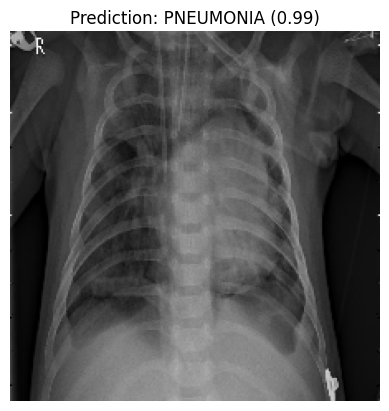

Prediction: PNEUMONIA
Confidence: 0.9893


In [37]:
predict_image("/content/extracted_images/chest_xray/test/PNEUMONIA/person100_bacteria_477.jpeg", best_model)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step


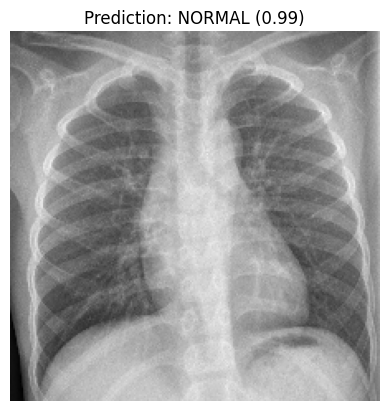

Prediction: NORMAL
Confidence: 0.9921


In [38]:
predict_image("/content/extracted_images/chest_xray/test/NORMAL/IM-0006-0001.jpeg", best_model)

In [39]:
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import Input, Conv2D, Flatten, Dense, Layer, BatchNormalization, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# Custom MAM Pooling Layer (TensorFlow version) - assuming this is defined elsewhere or in an earlier cell
# If not, it needs to be included here or imported.
# For the purpose of this fix, I'm assuming it's available.
class MAMPooling(Layer):
    def __init__(self, pool_size=2, strides=2):
        super(MAMPooling, self).__init__()
        self.pool_size = pool_size
        self.strides = strides

    def call(self, inputs):
        # Max, Min, Avg
        max_pool = tf.nn.max_pool2d(inputs, ksize=self.pool_size, strides=self.strides, padding='VALID')
        min_pool = -tf.nn.max_pool2d(-inputs, ksize=self.pool_size, strides=self.strides, padding='VALID')
        avg_pool = tf.nn.avg_pool2d(inputs, ksize=self.pool_size, strides=self.strides, padding='VALID')

        diff = max_pool - min_pool

        # Condition: if diff > avg → diff else (max+min)/2
        condition = tf.greater(diff, avg_pool)

        mam = tf.where(condition, diff, (max_pool + min_pool) / 2)

        return mam

In [41]:
import tensorflow as tf
from tensorflow.keras.layers import Layer

# Redefining MAMPooling with proper **kwargs support
class MAMPooling(Layer):
    def __init__(self, pool_size=2, strides=2, **kwargs):
        super(MAMPooling, self).__init__(**kwargs)
        self.pool_size = pool_size
        self.strides = strides

    def call(self, inputs):
        max_pool = tf.nn.max_pool2d(inputs, ksize=self.pool_size, strides=self.strides, padding='VALID')
        min_pool = -tf.nn.max_pool2d(-inputs, ksize=self.pool_size, strides=self.strides, padding='VALID')
        avg_pool = tf.nn.avg_pool2d(inputs, ksize=self.pool_size, strides=self.strides, padding='VALID')

        diff = max_pool - min_pool
        condition = tf.greater(diff, avg_pool)
        mam = tf.where(condition, diff, (max_pool + min_pool) / 2)
        return mam

# Test MAM Pooling
input_tensor = tf.random.normal((1, 8, 8, 3))

mam_layer = MAMPooling(
    pool_size=2,
    strides=2,
    name="mam_pooling"
)

output = mam_layer(input_tensor)

print("Input Shape:", input_tensor.shape)
print("Output Shape:", output.shape)
print("Output:", output)

Input Shape: (1, 8, 8, 3)
Output Shape: (1, 4, 4, 3)
Output: tf.Tensor(
[[[[0.50154984 0.74088013 1.180986  ]
   [3.476615   3.4666772  4.1299295 ]
   [3.3511877  1.8037212  1.2817864 ]
   [1.7424555  1.7039059  0.91237533]]

  [[0.7696156  1.8912978  3.2963629 ]
   [3.0995293  0.783302   2.7538297 ]
   [2.6611764  1.4419467  1.7544817 ]
   [2.963511   2.3425186  2.708828  ]]

  [[1.1171013  1.7171555  1.2906625 ]
   [1.1567186  0.8650553  2.3781028 ]
   [1.8066993  1.9066575  3.3881354 ]
   [3.5071378  1.5778371  2.6956043 ]]

  [[3.751944   1.352129   0.90059143]
   [2.259872   3.422667   1.1505868 ]
   [2.8583956  0.9215761  1.2646782 ]
   [0.6465143  2.7748806  3.1684146 ]]]], shape=(1, 4, 4, 3), dtype=float32)


In [44]:


#  Base VGG16
base_model = VGG16(weights='imagenet', include_top=False, input_tensor=Input(shape=(224,224,3)))

x = base_model.output # Output shape: (None, 7, 7, 512) for 224x224 input



# Block 2: Reduces 3x3 to 1x1
x = Conv2D(128, (3,3), activation='relu', padding='same')(x)
x = BatchNormalization()(x)
x = MAMPooling(pool_size=2, strides=2)(x) # Shape: (None, 1, 1, 128)



x = Conv2D(128, (3,3), activation='relu', padding='same')(x) # Shape: (None, 1, 1, 128)
x = BatchNormalization()(x)

#  Apply Global Average Pooling (as the feature map is already 1x1)
x = GlobalAveragePooling2D()(x) # Shape: (None, 128)

# Flatten is redundant after GlobalAveragePooling2D, as GAP2D outputs a 1D tensor.
# x = Flatten()(x)

# Output Layer
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(1, activation='sigmoid')(x)

# Final Model
model_mam_conv = Model(inputs=base_model.input, outputs=x)

# Compile
model_mam_conv.compile(
    optimizer=Adam(0.00001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Summary
model_mam_conv.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 7, 7, 128)      │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mam_pooling_2 (MAMPooling)      │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 3, 3, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 3, 3, 128)      │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 15,469,889 (59.01 MB)

 Trainable params: 15,469,377 (59.01 MB)

 Non-trainable params: 512 (2.00 KB)

In [46]:
# Train Model BEFORE Flatten
history_before = model_mam_conv.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10
)

Epoch 1/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 133s 1s/step - accuracy: 0.9282 - loss: 0.2613 - val_accuracy: 0.8087 - val_loss: 0.4541
Epoch 2/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 131s 1s/step - accuracy: 0.9404 - loss: 0.2091 - val_accuracy: 0.8707 - val_loss: 0.3380
Epoch 3/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 130s 1s/step - accuracy: 0.9544 - loss: 0.1686 - val_accuracy: 0.8914 - val_loss: 0.2937
Epoch 4/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 134s 1s/step - accuracy: 0.9587 - loss: 0.1484 - val_accuracy: 0.9204 - val_loss: 0.2177
Epoch 5/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 134s 1s/step - accuracy: 0.9679 - loss: 0.1181 - val_accuracy: 0.9518 - val_loss: 0.1408
Epoch 6/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 131s 1s/step - accuracy: 0.9654 - loss: 0.1143 - val_accuracy: 0.9770 - val_loss: 0.0904
Epoch 7/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 129s 1s/step - accuracy: 0.9720 - loss: 0.0963 - val_accuracy: 0.9342 - val_loss: 0.1813
Epoch 8/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 146s 1s/step - accuracy: 0.9687 - loss: 0.1039 - val_accu

In [47]:
loss,acc = model_mam_conv.evaluate(test_gen)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {acc:.2f}")

624/624 ━━━━━━━━━━━━━━━━━━━━ 17s 25ms/step - accuracy: 0.9167 - loss: 0.2211
Test Loss: 0.2211
Test Accuracy: 0.92


In [48]:

#  Load VGG16
base_model = VGG16(weights='imagenet', include_top=False, input_tensor=Input(shape=(224,224,3)))

x = base_model.output

#  Apply MAM Pooling BEFORE flatten
x = MAMPooling(pool_size=2, strides=2)(x)

# Flatten
x = GlobalAveragePooling2D()(x)

#  3 Increasing Dense Layers
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.3)(x)
x = Dense(512, activation='relu')(x)

# Output Layer
x = Dense(1, activation='sigmoid')(x)

# Final Model
model_final = Model(inputs=base_model.input, outputs=x)

# Compile
model_final.compile(
    optimizer=Adam(0.000001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Summary
model_final.summary()

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mam_pooling_3 (MAMPooling)      │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 14,945,473 (57.01 MB)

 Trainable params: 14,945,473 (57.01 MB)

 Non-trainable params: 0 (0.00 B)

In [49]:
# Train Model AFTER Flatten
# Re-compile with run_eagerly=True if graph tracing issues persist with custom layers
model_final.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss='binary_crossentropy',
    metrics=['accuracy'],
    run_eagerly=False
)

history_after = model_final.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10
)

Epoch 1/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 156s 1s/step - accuracy: 0.7847 - loss: 0.4062 - val_accuracy: 0.9212 - val_loss: 0.2204
Epoch 2/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 134s 1s/step - accuracy: 0.8971 - loss: 0.2602 - val_accuracy: 0.9457 - val_loss: 0.1360
Epoch 3/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 133s 1s/step - accuracy: 0.9251 - loss: 0.1934 - val_accuracy: 0.7337 - val_loss: 0.6382
Epoch 4/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 135s 1s/step - accuracy: 0.9335 - loss: 0.1790 - val_accuracy: 0.9503 - val_loss: 0.1250
Epoch 5/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 133s 1s/step - accuracy: 0.9473 - loss: 0.1393 - val_accuracy: 0.8837 - val_loss: 0.3056
Epoch 6/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 135s 1s/step - accuracy: 0.9557 - loss: 0.1276 - val_accuracy: 0.9694 - val_loss: 0.0908
Epoch 7/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 138s 1s/step - accuracy: 0.9595 - loss: 0.1239 - val_accuracy: 0.9166 - val_loss: 0.2005
Epoch 8/10
123/123 ━━━━━━━━━━━━━━━━━━━━ 136s 1s/step - accuracy: 0.9572 - loss: 0.1188 - val_accu

In [50]:
# Evaluate Model AFTER Flatten
print("\n Evaluating Model AFTER Flatten...")
loss_after, acc_after = model_final.evaluate(test_gen)


 Evaluating Model AFTER Flatten...
624/624 ━━━━━━━━━━━━━━━━━━━━ 16s 22ms/step - accuracy: 0.9311 - loss: 0.2085


In [51]:
import tensorflow as tf

# Evaluate Model BEFORE Flatten
print(" Evaluating Model BEFORE Flatten...")
loss_before, acc_before = model_mam_conv.evaluate(test_gen)

# Evaluate Model AFTER Flatten
print("\n Evaluating Model AFTER Flatten...")
loss_after, acc_after = model_final.evaluate(test_gen)

 Evaluating Model BEFORE Flatten...
624/624 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - accuracy: 0.9167 - loss: 0.2211

 Evaluating Model AFTER Flatten...
624/624 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step - accuracy: 0.9311 - loss: 0.2085


In [52]:
print("\n FINAL COMPARISON:")
print(f"Before Flatten → Loss: {loss_before:.4f}, Accuracy: {acc_before:.4f}")
print(f"After Flatten  → Loss: {loss_after:.4f}, Accuracy: {acc_after:.4f}")


 FINAL COMPARISON:
Before Flatten → Loss: 0.2211, Accuracy: 0.9167
After Flatten  → Loss: 0.2085, Accuracy: 0.9311


In [53]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# True labels
y_true = test_gen.classes

# Predictions (Before)
y_pred_before = model_mam_conv.predict(test_gen)
y_pred_before = (y_pred_before > 0.5).astype(int).reshape(-1)

# Predictions (After)
y_pred_after = model_final.predict(test_gen)
y_pred_after = (y_pred_after > 0.5).astype(int).reshape(-1)

#  BEFORE Flatten
print("\n BEFORE Flatten - Classification Report")
print(classification_report(y_true, y_pred_before))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred_before))


#  AFTER Flatten
print("\n AFTER Flatten - Classification Report")
print(classification_report(y_true, y_pred_after))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred_after))

624/624 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step
624/624 ━━━━━━━━━━━━━━━━━━━━ 14s 21ms/step

 BEFORE Flatten - Classification Report
              precision    recall  f1-score   support

           0       0.88      0.91      0.89       234
           1       0.94      0.92      0.93       390

    accuracy                           0.92       624
   macro avg       0.91      0.91      0.91       624
weighted avg       0.92      0.92      0.92       624

Confusion Matrix:
[[212  22]
 [ 30 360]]

 AFTER Flatten - Classification Report
              precision    recall  f1-score   support

           0       0.97      0.84      0.90       234
           1       0.91      0.98      0.95       390

    accuracy                           0.93       624
   macro avg       0.94      0.91      0.92       624
weighted avg       0.93      0.93      0.93       624

Confusion Matrix:
[[197  37]
 [  6 384]]


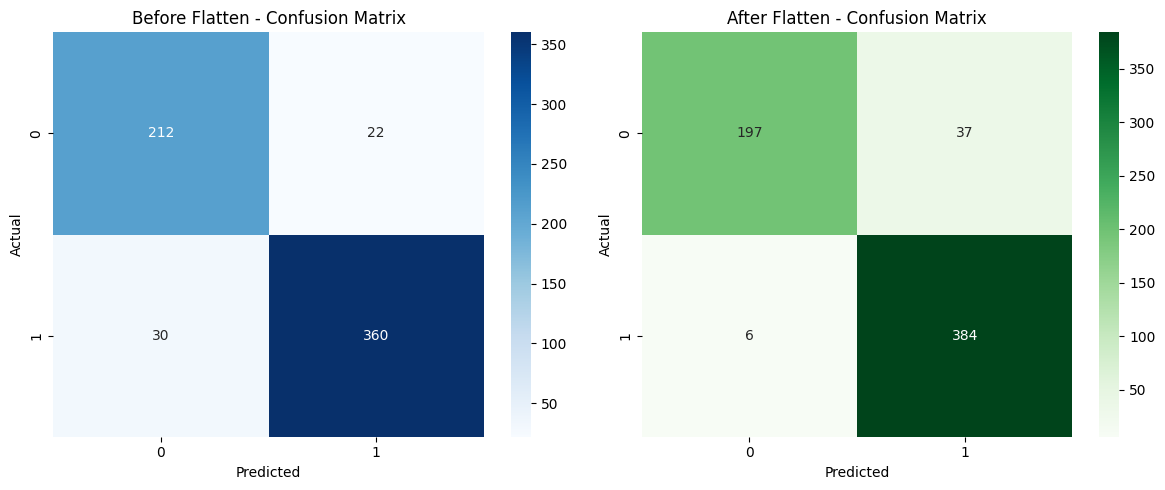

In [54]:
# Confusion matrices
cm_before = confusion_matrix(y_true, y_pred_before)
cm_after = confusion_matrix(y_true, y_pred_after)

#  Plot side by side
plt.figure(figsize=(12,5))

# BEFORE Flatten
plt.subplot(1,2,1)
sns.heatmap(cm_before, annot=True, fmt='d', cmap='Blues')
plt.title('Before Flatten - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# AFTER Flatten
plt.subplot(1,2,2)
sns.heatmap(cm_after, annot=True, fmt='d', cmap='Greens')
plt.title('After Flatten - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.tight_layout()
plt.show()

624/624 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step
624/624 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step


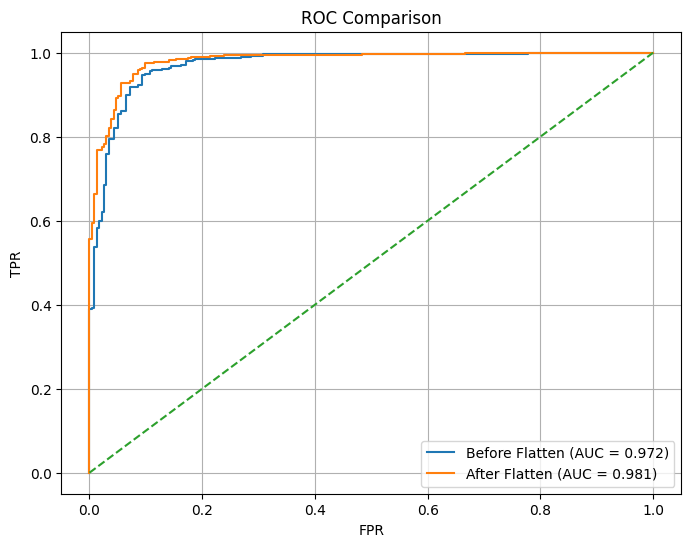

In [55]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

test_gen.reset()

# Probabilities (NOT thresholded)
y_prob_before = model_mam_conv.predict(test_gen).ravel()
y_prob_after = model_final.predict(test_gen).ravel()

y_true = test_gen.classes

# ROC
fpr_b, tpr_b, _ = roc_curve(y_true, y_prob_before)
auc_b = auc(fpr_b, tpr_b)

fpr_a, tpr_a, _ = roc_curve(y_true, y_prob_after)
auc_a = auc(fpr_a, tpr_a)

# Plot
plt.figure(figsize=(8,6))
plt.plot(fpr_b, tpr_b, label=f'Before Flatten (AUC = {auc_b:.3f})')
plt.plot(fpr_a, tpr_a, label=f'After Flatten (AUC = {auc_a:.3f})')
plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC Comparison")
plt.legend()
plt.grid()
plt.show()

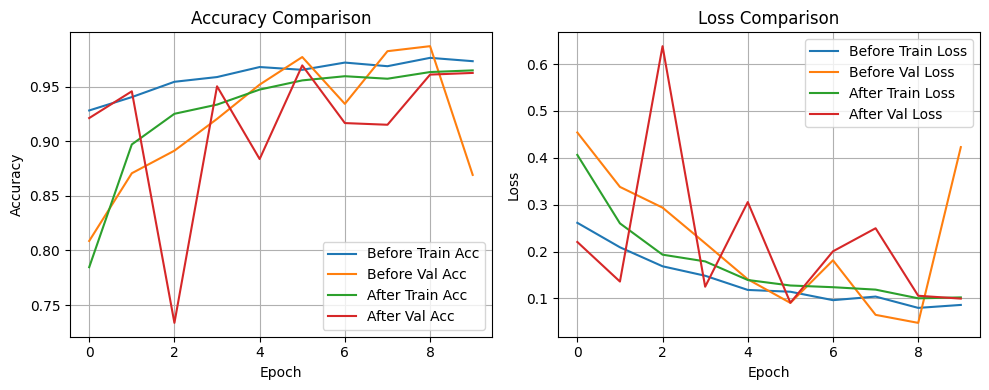

In [56]:
import matplotlib.pyplot as plt

#  Accuracy Plot
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history_before.history['accuracy'], label='Before Train Acc')
plt.plot(history_before.history['val_accuracy'], label='Before Val Acc')

plt.plot(history_after.history['accuracy'], label='After Train Acc')
plt.plot(history_after.history['val_accuracy'], label='After Val Acc')

plt.title('Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

#  Loss Plot
plt.subplot(1,2,2)
plt.plot(history_before.history['loss'], label='Before Train Loss')
plt.plot(history_before.history['val_loss'], label='Before Val Loss')

plt.plot(history_after.history['loss'], label='After Train Loss')
plt.plot(history_after.history['val_loss'], label='After Val Loss')

plt.title('Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [57]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    balanced_accuracy_score,
    cohen_kappa_score,
    log_loss,
    brier_score_loss
)

def evaluate_research_metrics(
    y_true,
    y_prob,
    model_name,
    threshold=0.5
):

    y_true = np.asarray(y_true).astype(int).ravel()
    y_prob = np.asarray(y_prob).astype(float).ravel()

    # Convert probabilities into binary predictions
    y_pred = (y_prob >= threshold).astype(int)

    # Confusion Matrix
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    # Basic Metrics
    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true, y_pred, zero_division=0
    )

    sensitivity = recall_score(
        y_true, y_pred, zero_division=0
    )

    specificity = tn / (tn + fp) if (tn + fp) else 0

    f1 = f1_score(y_true, y_pred, zero_division=0)

    # Additional Metrics
    npv = tn / (tn + fn) if (tn + fn) else 0

    fpr = fp / (fp + tn) if (fp + tn) else 0

    fnr = fn / (fn + tp) if (fn + tp) else 0

    mcc = matthews_corrcoef(y_true, y_pred)

    balanced_acc = balanced_accuracy_score(y_true, y_pred)

    kappa = cohen_kappa_score(y_true, y_pred)

    # Probability Metrics
    roc_auc = roc_auc_score(y_true, y_prob)

    pr_auc = average_precision_score(y_true, y_prob)

    logloss = log_loss(
        y_true, y_prob, labels=[0, 1]
    )

    brier = brier_score_loss(y_true, y_prob)

    results = {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "F1-Score": f1,
        "NPV": npv,
        "MCC": mcc,
        "Balanced Accuracy": balanced_acc,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc,
        "Cohen Kappa": kappa,
        "FPR": fpr,
        "FNR": fnr,
        "Log Loss": logloss,
        "Brier Score": brier,
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn
    }

    print("\n" + "=" * 65)
    print(f"{model_name} - RESEARCH EVALUATION")
    print("=" * 65)

    for metric, value in results.items():
        if isinstance(value, (float, np.floating)):
            print(f"{metric:22s}: {value:.4f}")
        else:
            print(f"{metric:22s}: {value}")

    print("\nClassification Report:")

    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Normal", "Pneumonia"],
        zero_division=0
    ))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

    return results


In [58]:

# ==========================================
# MODEL 1: BEFORE FLATTEN
# ==========================================

y_true = test_gen.classes

prob_before = model_mam_conv.predict(
    test_gen,
    verbose=1
).ravel()

results_before = evaluate_research_metrics(
    y_true=y_true,
    y_prob=prob_before,
    model_name="MAM Before Flatten"
)


# ==========================================
# MODEL 2: AFTER FLATTEN
# ==========================================

prob_after = model_final.predict(
    test_gen,
    verbose=1
).ravel()

results_after = evaluate_research_metrics(
    y_true=y_true,
    y_prob=prob_after,
    model_name="MAM After Flatten"
)


624/624 ━━━━━━━━━━━━━━━━━━━━ 22s 35ms/step

MAM Before Flatten - RESEARCH EVALUATION
Model                 : MAM Before Flatten
Accuracy              : 0.9167
Precision             : 0.9424
Sensitivity           : 0.9231
Specificity           : 0.9060
F1-Score              : 0.9326
NPV                   : 0.8760
MCC                   : 0.8237
Balanced Accuracy     : 0.9145
ROC-AUC               : 0.9717
PR-AUC                : 0.9808
Cohen Kappa           : 0.8234
FPR                   : 0.0940
FNR                   : 0.0769
Log Loss              : 0.2211
Brier Score           : 0.0602
TP                    : 360
TN                    : 212
FP                    : 22
FN                    : 30

Classification Report:
              precision    recall  f1-score   support

      Normal       0.88      0.91      0.89       234
   Pneumonia       0.94      0.92      0.93       390

    accuracy                           0.92       624
   macro avg       0.91      0.91      0.91       624
w

In [59]:

# Combine both model results

comparison_df = pd.DataFrame([
    results_before,
    results_after
])

print("\nFINAL MODEL COMPARISON")

print(
    comparison_df.to_string(
        index=False
    )
)

# Save results for research paper
comparison_df.to_csv(
    "MAM_Before_After_Flatten_Comparison.csv",
    index=False
)

comparison_df.to_excel(
    "MAM_Before_After_Flatten_Comparison.xlsx",
    index=False
)



FINAL MODEL COMPARISON
             Model  Accuracy  Precision  Sensitivity  Specificity  F1-Score      NPV      MCC  Balanced Accuracy  ROC-AUC   PR-AUC  Cohen Kappa      FPR      FNR  Log Loss  Brier Score  TP  TN  FP  FN
MAM Before Flatten  0.916667   0.942408     0.923077     0.905983  0.932642 0.876033 0.823734           0.914530 0.971685 0.980832      0.82343 0.094017 0.076923  0.221125     0.060196 360 212  22  30
 MAM After Flatten  0.931090   0.912114     0.984615     0.841880  0.946979 0.970443 0.854067           0.913248 0.980945 0.988114      0.84899 0.158120 0.015385  0.208510     0.057535 384 197  37   6


In [62]:
# BOOTSTRAP
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

def bootstrap_confidence_interval(
    y_true,
    y_pred,
    y_prob,
    n_iterations=2000,
    random_state=42
):

    y_true = np.asarray(y_true).astype(int).ravel()
    y_pred = np.asarray(y_pred).astype(int).ravel()
    y_prob = np.asarray(y_prob).astype(float).ravel()

    if not (len(y_true) == len(y_pred) == len(y_prob)):
        raise ValueError("Input arrays must have equal lengths.")

    rng = np.random.default_rng(random_state)

    scores = {
        "Accuracy": [],
        "Sensitivity": [],
        "Specificity": [],
        "F1-Score": [],
        "ROC-AUC": []
    }

    n = len(y_true)

    for _ in range(n_iterations):

        idx = rng.integers(0, n, size=n)

        yt = y_true[idx]
        yp = y_pred[idx]
        ypr = y_prob[idx]

        # Both classes must be present
        if len(np.unique(yt)) < 2:
            continue

        tn, fp, fn, tp = confusion_matrix(
            yt, yp, labels=[0, 1]
        ).ravel()

        scores["Accuracy"].append(
            accuracy_score(yt, yp)
        )

        scores["Sensitivity"].append(
            recall_score(yt, yp, zero_division=0)
        )

        scores["Specificity"].append(
            tn / (tn + fp) if (tn + fp) else np.nan
        )

        scores["F1-Score"].append(
            f1_score(yt, yp, zero_division=0)
        )

        scores["ROC-AUC"].append(
            roc_auc_score(yt, ypr)
        )

    ci_results = {}

    for metric, values in scores.items():

        values = np.asarray(values, dtype=float)
        values = values[np.isfinite(values)]

        if len(values) == 0:
            ci_results[metric] = {
                "Lower 95% CI": np.nan,
                "Upper 95% CI": np.nan
            }
            continue

        lower, upper = np.percentile(
            values, [2.5, 97.5]
        )

        ci_results[metric] = {
            "Lower 95% CI": lower,
            "Upper 95% CI": upper
        }

    return pd.DataFrame(ci_results).T


In [61]:

# ==========================================
#  BOOTSTRAP BEFORE FLATTEN MODEL
# ==========================================

y_true = test_gen.classes

prob_before = model_mam_conv.predict(
    test_gen,
    verbose=1
).ravel()

pred_before = (prob_before >= 0.5).astype(int)

before_ci = bootstrap_confidence_interval(
    y_true=y_true,
    y_pred=pred_before,
    y_prob=prob_before,
    n_iterations=2000,
    random_state=42
)

print("\nMAM BEFORE FLATTEN - 95% BOOTSTRAP CI")

display(before_ci.round(4))


624/624 ━━━━━━━━━━━━━━━━━━━━ 23s 37ms/step

MAM BEFORE FLATTEN - 95% BOOTSTRAP CI


,Lower 95% CI,Upper 95% CI
Accuracy,0.8926,0.9375
Sensitivity,0.8953,0.9478
Specificity,0.8661,0.9436
F1-Score,0.9130,0.9501
ROC-AUC,0.9585,0.9834


In [63]:

# ==========================================
#  BOOTSTRAP AFTER FLATTEN MODEL
# ==========================================

prob_after = model_final.predict(
    test_gen,
    verbose=1
).ravel()

pred_after = (prob_after >= 0.5).astype(int)

after_ci = bootstrap_confidence_interval(
    y_true=y_true,
    y_pred=pred_after,
    y_prob=prob_after,
    n_iterations=2000,
    random_state=42
)

print("\nMAM AFTER FLATTEN - 95% BOOTSTRAP CI")

display(after_ci.round(4))


624/624 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step

MAM AFTER FLATTEN - 95% BOOTSTRAP CI


,Lower 95% CI,Upper 95% CI
Accuracy,0.9103,0.9503
Sensitivity,0.9711,0.9950
Specificity,0.7947,0.8871
F1-Score,0.9309,0.9625
ROC-AUC,0.9708,0.9896


In [64]:

# ==========================================
# COMPARATIVE 95% BOOTSTRAP CI
# ==========================================

comparison_ci = pd.concat(
    {
        "MAM Before Flatten": before_ci,
        "MAM After Flatten": after_ci
    },
    axis=1
)

print("\nFINAL BOOTSTRAP CONFIDENCE INTERVAL COMPARISON")

display(comparison_ci.round(4))

# Save results
comparison_ci.to_csv(
    "MAM_Bootstrap_CI_Comparison.csv"
)

comparison_ci.to_excel(
    "MAM_Bootstrap_CI_Comparison.xlsx"
)



FINAL BOOTSTRAP CONFIDENCE INTERVAL COMPARISON


MAM Before Flatten              MAM After Flatten             
                  Lower 95% CI Upper 95% CI      Lower 95% CI Upper 95% CI
Accuracy                0.8926       0.9375            0.9103       0.9503
Sensitivity             0.8953       0.9478            0.9711       0.9950
Specificity             0.8661       0.9436            0.7947       0.8871
F1-Score                0.9130       0.9501            0.9309       0.9625
ROC-AUC                 0.9585       0.9834            0.9708       0.9896

In [65]:

import numpy as np
import pandas as pd

from sklearn.metrics import confusion_matrix

# Actual test labels
y_true = test_gen.classes

# Predictions from both models
all_predictions = {
    "MAM Before Flatten": pred_before,
    "MAM After Flatten": pred_after
}

results = []

for model_name, y_pred in all_predictions.items():

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    # Sensitivity
    sensitivity = (
        tp / (tp + fn) if (tp + fn) else 0
    )

    # Specificity
    specificity = (
        tn / (tn + fp) if (tn + fp) else 0
    )

    results.append({
        "Model": model_name,
        "Sensitivity (%)": sensitivity * 100,
        "Specificity (%)": specificity * 100
    })

results_df = pd.DataFrame(results)

print("\nBEFORE vs AFTER FLATTEN COMPARISON")

display(results_df.round(2))



BEFORE vs AFTER FLATTEN COMPARISON


,Model,Sensitivity (%),Specificity (%)
0,MAM Before Flatten,92.31,90.60
1,MAM After Flatten,98.46,84.19


In [67]:
#  Store accuracies properly
accuracies = {
    "Before Flatten": acc_before,
    "After Flatten": acc_after
}

#  Store models
models = {
    "Before Flatten": model_mam_conv,
    "After Flatten": model_final
}

#  Select best model
best_model_name = max(accuracies, key=accuracies.get)
best_model = models[best_model_name]

print(" Best Model:", best_model_name)

 Best Model: After Flatten


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor_771']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


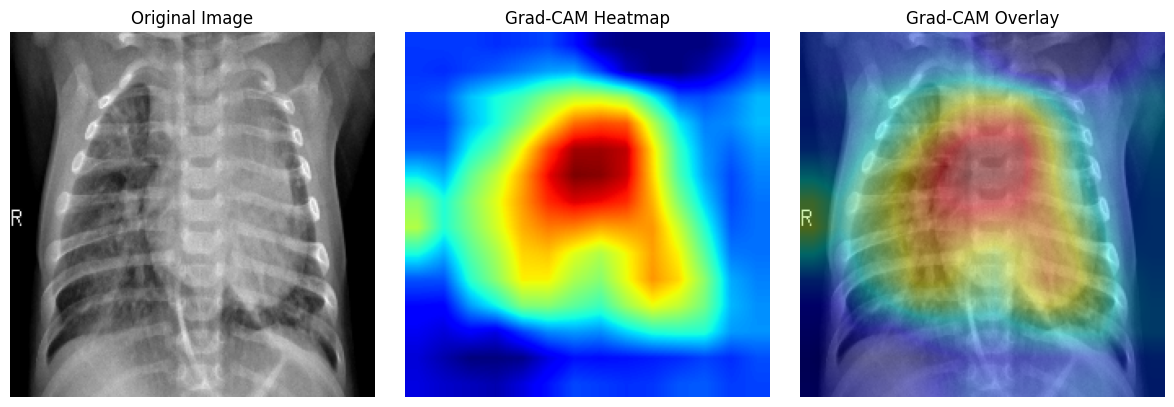

In [68]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

# Re-load the image used for prediction and define original_img for plotting
# Using the image path from a previous successful prediction:
img_path = "/content/extracted_images/chest_xray/test/PNEUMONIA/person100_bacteria_475.jpeg"

# Load image for display (cv2.imread reads as BGR)
original_img = cv2.imread(img_path)
original_img = cv2.resize(original_img, (224, 224)) # Resize to match model input expectation

# Preprocess image for model input
img_model = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img_model)
img_array = np.expand_dims(img_array, axis=0) # Add batch dimension
img_array = img_array / 255.0 # Normalize to [0, 1] as models are typically trained this way

# Assuming 'best_model' is already defined from previous cells (which is 'model_final')

# Define the last convolutional layer name from the VGG16 base model
# This layer is part of the 'best_model' (model_final)
last_conv_layer_name = 'block5_conv3'

# Create a Grad-CAM model that outputs:
# 1. Activations from the last convolutional layer
# 2. Final predictions from the model
grad_model = tf.keras.models.Model(
    [best_model.inputs], [best_model.get_layer(last_conv_layer_name).output, best_model.output]
)

# Use tf.GradientTape to record operations for automatic differentiation
with tf.GradientTape() as tape:
    # Forward pass: get activations of the last conv layer and model predictions
    last_conv_layer_output, preds = grad_model(img_array)
    # Get the predicted class index (most confident prediction)
    pred_index = tf.argmax(preds[0])
    # Get the score for the predicted class
    class_channel = preds[:, pred_index]

# Calculate gradients of the predicted class score with respect to the last conv layer's activations
grads = tape.gradient(class_channel, last_conv_layer_output)

# Global average pooling of gradients: average the gradients across spatial dimensions
pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

# Multiply each channel in the feature map by the corresponding gradient weight
conv_outputs_for_heatmap = last_conv_layer_output[0]
heatmap = conv_outputs_for_heatmap @ pooled_grads[..., tf.newaxis]
heatmap = tf.squeeze(heatmap) # Remove the last dimension of size 1

# Normalize the heatmap: apply ReLU to keep only positive contributions and scale to [0, 1]
heatmap = tf.maximum(heatmap, 0)
# Handle potential division by zero if heatmap is all zeros
if tf.math.reduce_max(heatmap) == 0:
    normalized_heatmap = heatmap
else:
    normalized_heatmap = heatmap / tf.math.reduce_max(heatmap)
normalized_heatmap = normalized_heatmap.numpy() # Convert to numpy for cv2

# Resize heatmap to match the original image size (224, 224)
heatmap_resized = cv2.resize(normalized_heatmap, (224, 224))

# Convert heatmap to a color map (JET is common for Grad-CAM)
heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)

# Superimpose heatmap on the original image
# Convert original_img to float and scale (0-255) for blending
# Ensure original_img is also 224x224 and then convert to float for blending
superimposed_img = heatmap_color * 0.4 + original_img.astype('float32') * 0.6
superimposed_img = np.clip(superimposed_img, 0, 255).astype('uint8') # Clip values to [0, 255] and convert to uint8

#  Plot all
plt.figure(figsize=(12,4))

# Original Image
plt.subplot(1,3,1)
plt.imshow(cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)) # cv2 reads as BGR, convert to RGB for matplotlib
plt.title("Original Image")
plt.axis('off')

# Heatmap
plt.subplot(1,3,2)
plt.imshow(heatmap_resized, cmap='jet')
plt.title("Grad-CAM Heatmap")
plt.axis('off')

# Overlay
plt.subplot(1,3,3)
plt.imshow(cv2.cvtColor(superimposed_img, cv2.COLOR_BGR2RGB)) # Convert BGR superimposed image to RGB
plt.title("Grad-CAM Overlay")
plt.axis('off')

plt.tight_layout()
plt.show()